cell_typemetadatasource

## 1. Import libraries

In [ ]:
import os
import zipfile
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import files

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


cell_typemetadatasource

In [ ]:
uploaded = files.upload()  # Select your dataset .zip file

zip_name = None
for file_name in uploaded.keys():
    if file_name.lower().endswith(".zip"):
        zip_name = file_name
        break

if zip_name is not None:
    extract_folder = "/content/waste_dataset"
    os.makedirs(extract_folder, exist_ok=True)

    with zipfile.ZipFile(zip_name, "r") as zip_ref:
        zip_ref.extractall(extract_folder)

    print("Dataset extracted to:", extract_folder)
else:
    print("No ZIP file was uploaded. If you uploaded individual images, organize them into class folders first.")

Saving waste_dataset_small.zip to waste_dataset_small.zip
Dataset extracted to: /content/waste_dataset


cell_typemetadatasource

In [ ]:
# Common image file formats
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

# Change this path only if your dataset is already extracted somewhere else.
dataset_path = "/content/waste_dataset"


def count_images(folder):
    count = 0
    for root, dirs, files_list in os.walk(folder):
        count += sum(name.lower().endswith(image_extensions) for name in files_list)
    return count

# Search for a folder whose direct subfolders contain images.
possible_folders = []
for root, dirs, files_list in os.walk(dataset_path):
    class_folders = []
    for folder_name in dirs:
        folder_full_path = os.path.join(root, folder_name)
        if count_images(folder_full_path) > 0:
            class_folders.append(folder_name)
    if len(class_folders) >= 2:
        possible_folders.append((root, class_folders))

if possible_folders:
    # Prefer the folder with the greatest number of class folders.
    possible_folders.sort(key=lambda item: len(item[1]), reverse=True)
    dataset_path, found_classes = possible_folders[0]
    print("Dataset folder:", dataset_path)
    print("Class folders found:", found_classes)
else:
    raise ValueError("Could not automatically find class folders. Check the ZIP structure and set dataset_path to the folder containing one subfolder per class.")

Dataset folder: /content/waste_dataset/TEST
Class folders found: ['R', 'O', 'E']


cell_typemetadatasource

In [ ]:
image_size = (128, 128)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="int"
)

class_names = train_ds.class_names
number_of_classes = len(class_names)
print("Waste categories:", class_names)
print("Number of categories:", number_of_classes)

Found 426 files belonging to 3 classes.
Using 341 files for training.
Found 426 files belonging to 3 classes.
Using 85 files for validation.
Waste categories: ['E', 'O', 'R']
Number of categories: 3


cell_typemetadatasource

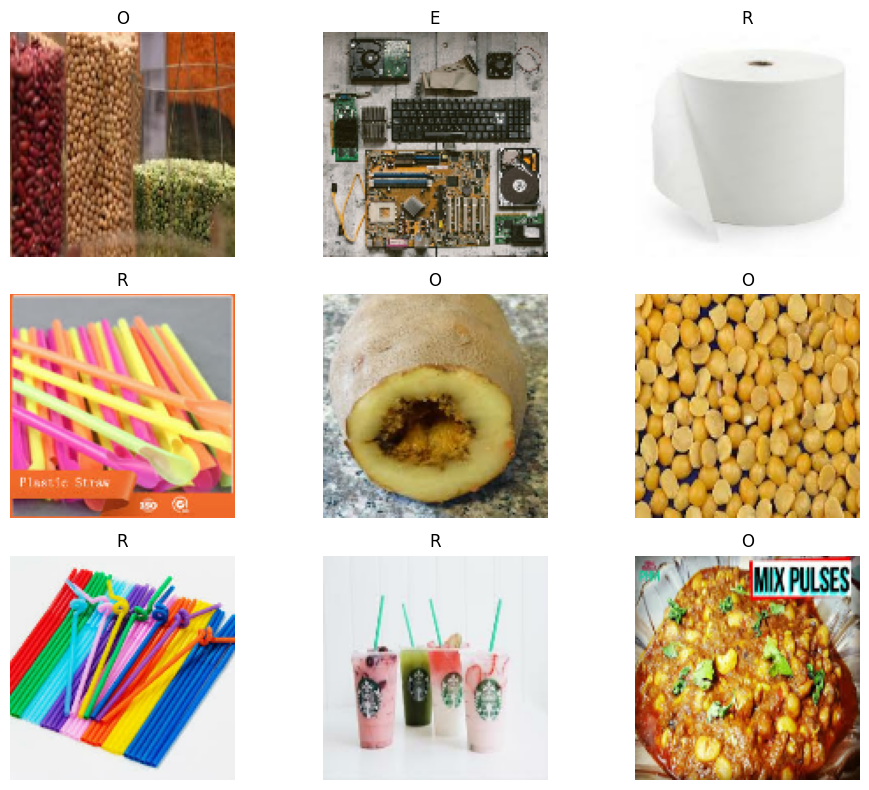

In [ ]:
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.tight_layout()
plt.show()

cell_typemetadatasource

In [ ]:
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

train_ds = train_ds.map(lambda images, labels: (normalization_layer(images), labels))
val_ds = val_ds.map(lambda images, labels: (normalization_layer(images), labels))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

print("Images are resized and normalized.")

Images are resized and normalized.


cell_typemetadatasource

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(number_of_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

cell_typemetadatasource

In [ ]:
epochs = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.5337 - loss: 1.2344 - val_accuracy: 0.8118 - val_loss: 0.6788
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.7683 - loss: 0.6656 - val_accuracy: 0.8118 - val_loss: 0.5334
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.8006 - loss: 0.5562 - val_accuracy: 0.8118 - val_loss: 0.5281
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.8182 - loss: 0.4967 - val_accuracy: 0.8118 - val_loss: 0.5109
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.8622 - loss: 0.4032 - val_accuracy: 0.8000 - val_loss: 0.5162
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.8416 - loss: 0.4064 - val_accuracy: 0.9412 - val_loss: 0.2477
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.9003 - loss: 0.2903 - val_accuracy: 0.9647 - val_loss: 0.1913
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.9179 - loss: 0.2429 - val_accuracy: 0.9529 - val_loss:

## 9. Plot accuracy and loss

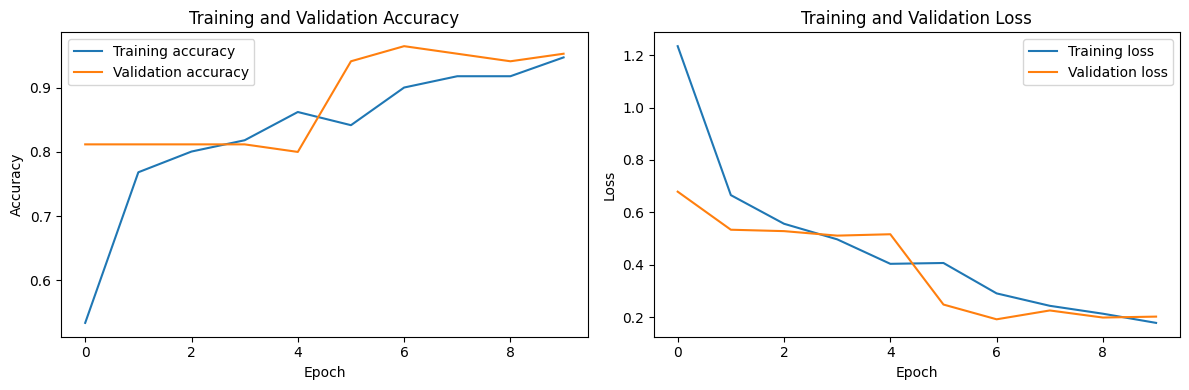

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

cell_typemetadatasource

In [ ]:
val_loss, val_accuracy = model.evaluate(val_ds, verbose=1)
print("Validation loss:", round(val_loss, 4))
print("Validation accuracy:", round(val_accuracy * 100, 2), "%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 352ms/step - accuracy: 0.9529 - loss: 0.2016
Validation loss: 0.2016
Validation accuracy: 95.29 %


## 11. Confusion matrix and classification report

              precision    recall  f1-score   support

           E       1.00      1.00      1.00         4
           O       0.93      0.97      0.95        39
           R       0.97      0.93      0.95        42

    accuracy                           0.95        85
   macro avg       0.97      0.97      0.97        85
weighted avg       0.95      0.95      0.95        85



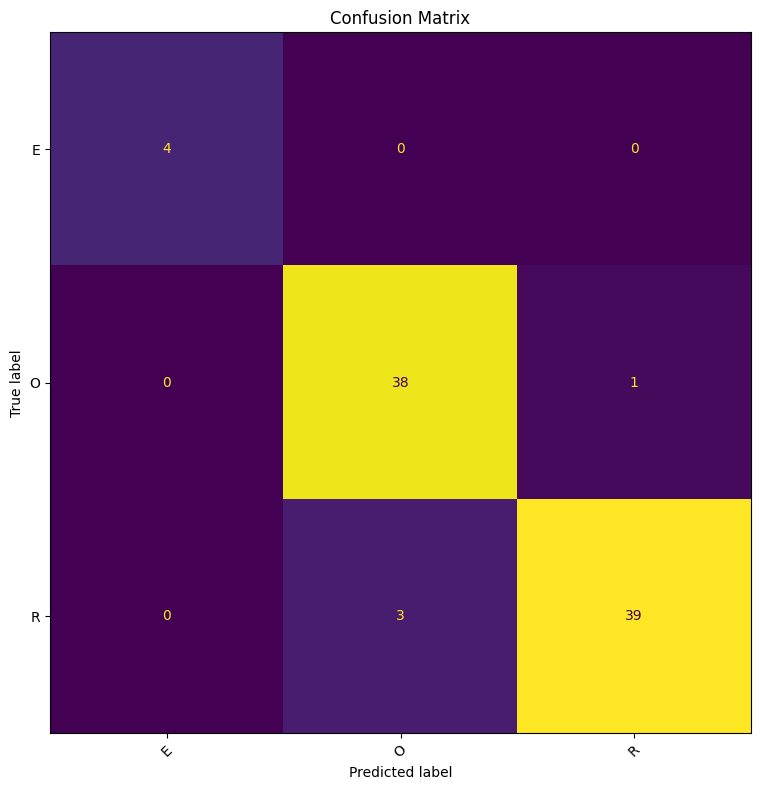

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

true_labels = []
predicted_labels = []

for images, labels in val_ds:
    probabilities = model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    true_labels.extend(labels.numpy())
    predicted_labels.extend(predictions)

print(classification_report(
    true_labels,
    predicted_labels,
    labels=list(range(number_of_classes)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(true_labels, predicted_labels, labels=list(range(number_of_classes)))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
display.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

cell_typemetadatasource

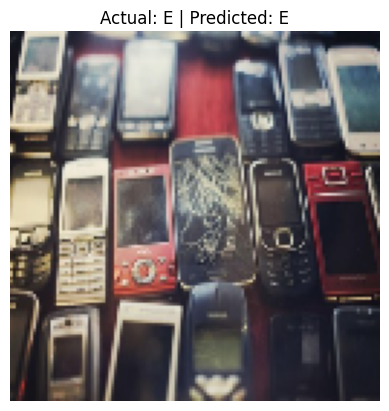

Actual category: E
Predicted category: E
Model confidence: 35.5 %


In [ ]:
for images, labels in val_ds.take(1):
    sample_image = images[0]
    actual_label = int(labels[0])

    probabilities = model.predict(tf.expand_dims(sample_image, axis=0), verbose=0)[0]
    predicted_label = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_label]) * 100

    plt.imshow(sample_image.numpy())
    plt.axis("off")
    plt.title("Actual: " + class_names[actual_label] + " | Predicted: " + class_names[predicted_label])
    plt.show()

    print("Actual category:", class_names[actual_label])
    print("Predicted category:", class_names[predicted_label])
    print("Model confidence:", round(confidence, 2), "%")

## 13. Real-world feature: sorting guidance for a new photo




Saving WhatsApp Image 2026-10-11 at 10.56.12 PM.jpeg to WhatsApp Image 2026-10-11 at 10.56.12 PM.jpeg


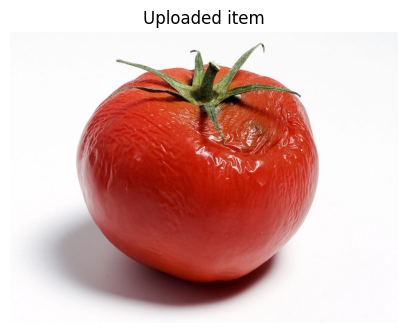

Predicted category: O
Model confidence score: 89.77 %
Suggested next step: The model recognized this dataset category, but no specific sorting rule is mapped to its name. Check local guidance or ask a waste-management staff member.
Reminder: This is a prototype. Confirm the material and local recycling rules before disposal.


In [ ]:
from google.colab import files
from PIL import Image
import io

# General guidance only; follow your local waste collection rules.
def get_sorting_advice(label):
    label_text = label.lower().replace("_", " ").replace("-", " ")

    if "cardboard" in label_text:
        return "Usually place in paper/cardboard recycling if clean and dry. Remove excessive tape or food contamination where local rules ask."
    elif "paper" in label_text:
        return "Usually place clean, dry paper in paper recycling. Greasy or wet paper may not be accepted."
    elif "plastic" in label_text:
        return "Check the plastic type and local recycling rules. Empty and rinse the container if appropriate; not every plastic item is recyclable locally."
    elif "glass" in label_text:
        return "Use the designated glass collection point if available. Handle broken glass carefully and follow local safety instructions."
    elif "metal" in label_text or "can" in label_text or "aluminium" in label_text or "aluminum" in label_text:
        return "Empty the item and use the metal-can recycling stream if accepted locally. Sharp edges should be handled carefully."
    elif "trash" in label_text or "garbage" in label_text or "organic" in label_text or "food" in label_text:
        return "Check whether your local system has a separate general-waste or compost/organic-waste stream. Do not assume all items in this class belong together."
    else:
        return "The model recognized this dataset category, but no specific sorting rule is mapped to its name. Check local guidance or ask a waste-management staff member."

# Upload one photo from your computer. Run this cell each time you want to test a new image.
uploaded_photo = files.upload()

for photo_name in uploaded_photo.keys():
    try:
        image = Image.open(io.BytesIO(uploaded_photo[photo_name])).convert("RGB")
        image_for_model = image.resize(image_size)
        image_array = np.array(image_for_model, dtype=np.float32) / 255.0
        image_array = np.expand_dims(image_array, axis=0)

        prediction_scores = model.predict(image_array, verbose=0)[0]
        predicted_index = int(np.argmax(prediction_scores))
        predicted_category = class_names[predicted_index]
        confidence = float(prediction_scores[predicted_index]) * 100

        plt.figure(figsize=(5, 5))
        plt.imshow(image)
        plt.axis("off")
        plt.title("Uploaded item")
        plt.show()

        print("Predicted category:", predicted_category)
        print("Model confidence score:", round(confidence, 2), "%")

        if confidence < 60:
            print("Decision: Please check this item manually (low model confidence).")
        else:
            print("Suggested next step:", get_sorting_advice(predicted_category))

        print("Reminder: This is a prototype. Confirm the material and local recycling rules before disposal.")
    except Exception as error:
        print("Could not process this file. Please upload a JPG or PNG image.")
        print("Details:", error)


## 15. Save the trained model

In [ ]:
model.save("smart_waste_cnn.keras")
print("Model saved as smart_waste_cnn.keras")

Model saved as smart_waste_cnn.keras
